# Import

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import smplotlib

findfont: Failed to find font weight normal, now using 500.


# Path and constants

In [2]:
gotberg19_path = Path("/Users/dexbhadra/Documents/delphi/delphi25_valentin/600_trees/goetberg19")
metallicities = ["0.014", "0.006", "0.002", "0.0002"]                         # the four G19 metallicities (0.014 = solar)
suffix = {"0.014": "014", "0.006": "006", "0.002": "002", "0.0002": "0002"}   # file name endings of nbrs*.dat and q*.dat
c_A = 2.99792458e18            # speed of light [Angstrom / s]
eV_A = 12398.42                # photon energy E [eV] = 12398.42 / wavelength [A]
lam_H = 911.75                 # hydrogen ionization edge [A] (13.6 eV)
Z_color = {"0.014": "#D60270", "0.006": "#9B4F96", "0.002": "#0038A8", "0.0002": "#000000"}   # bisexual flag + black
age_color = {11: "#FF218C", 20: "#FFD800", 50: "#21B1FF", 100: "#000000"}                       # pansexual flag + black

# Reading the files

* nbrs*.dat: number of stripped stars present after the burst, against time.
* q*.dat: $\log_{10}$ of the ionizing photon rates Q0 (H), Q1 (He I), Q2 (He II) after the burst; $-30$ means no stripped stars.
* sed/SED_Z*_starburst.txt and `_constant.txt: the stripped-star spectrum $L_\lambda$ [erg/s/Å], 100-10 000 Å, at 500 times
  from 1 Myr to 3 Gyr. The first row holds the wavelengths, every other row one time.

In [3]:
def read_counts(Z):
    #the number of stripped stars present after a 1e6 Msun burst
    names = ["time", "total", "caseA", "caseB", "BCEE", "above10", "above5", "above3"]
    return pd.read_csv(gotberg19_path / f"nbrs{suffix[Z]}.dat", sep=r"\s+", comment="#", names=names)

def read_q(Z):
    # the photon rates Q0 (H), Q1 (He I), Q2 (He II) [1/s] after a 1e6 Msun burst.
    # log10 Q = -30 when there are no stripped stars, so 10**(-30) is effectively zero.
    q = pd.read_csv(gotberg19_path / f"q{suffix[Z]}.dat", sep=r"\s+", comment="#", names=["time", "Q0", "Q1", "Q2"])
    q[["Q0", "Q1", "Q2"]] = 10.0 ** q[["Q0", "Q1", "Q2"]]
    return q

def read_spectra(path):
    # first row: 0, then the wavelengths [A]; 
    #every other row: time [yr], then L_lambda [erg/s/A] at each wavelength
    table = pd.read_csv(path, sep=r"\s+", comment="#", header=None).to_numpy()
    return table[1:, 0], table[0, 1:], table[1:, 1:]          # time, wavelength, luminosity (time x wavelength)

# The G19 stripped-star spectra used in the plots below are the burst files, SED_Z*_starburst.txt (G19's CDS files):
# L_lambda of the stripped stars only, for a burst of 1e6 Msun, 100-10 000 A, at 500 ages from 1 Myr to 3 Gyr.
# (They are identical to the stripped-star files in published_runs_SB99.) The _constant files are read too, but not used.
burst, constant = {}, {}
for Z in metallicities:
    burst[Z] = read_spectra(gotberg19_path / "sed" / f"SED_Z{Z}_starburst.txt")
    constant[Z] = read_spectra(gotberg19_path / "sed" / f"SED_Z{Z}_constant.txt")

# Number of stripped stars

After a burst of $10^6\,M_\odot$. Dotted lines: one and two DELPHI steps (29.6 and 59.2 Myr).

findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight normal, now using 500.
findfont: Failed to find font weight bold, now using 800.


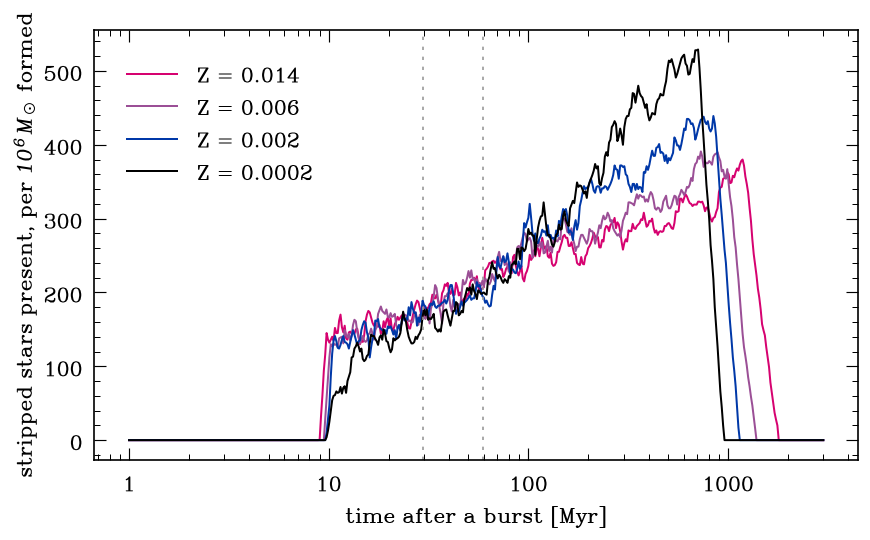

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for Z in metallicities:
    counts = read_counts(Z)
    ax.plot(counts["time"] / 1e6, counts["total"], color=Z_color[Z], label=f"Z = {Z}")
for delphi_step in (29.6, 59.2):
    ax.axvline(delphi_step, color="0.6", ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("time after a burst [Myr]")
ax.set_ylabel(r"stripped stars present, per $10^6\,M_\odot$ formed")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

# The whole population: single + stripped stars

G19's Fig. 7 shows the whole population: the single stars (Starburst99) plus the stripped stars. 

* These files give $\log_{10} L_\lambda$ for **constant** star formation at 1 $M_\odot$/yr. The light of a $10^6\,M_\odot$ burst at age $t$
  is $10^6$ times how fast that light grows: $L_{\rm burst}(t) = 10^6 \times [L_{\rm const}(t + 0.05\,{\rm Myr}) - L_{\rm const}(t - 0.05\,{\rm Myr})] / 0.1\,{\rm Myr}$.
* Starburst99 metallicities, as in G19 (Table A.1): 0.014, 0.008, 0.002, 0.001 for the stripped stars at 0.014, 0.006, 0.002, 0.0002.
* Single stars only: 2, 5 and 10 Myr. Single + stripped stars: 11, 20, 50 and 100 Myr.
* Grey band: AGN, $L_\nu \propto \nu^{\alpha}$ with $-2 < \alpha < -1.2$. Dotted lines: the ionization edges of H (13.6 eV),
  He I (24.6 eV) and He II (54.4 eV). The regions under the spectra are not shaded.

In [21]:
sb99_path = Path("/Users/dexbhadra/Documents/delphi/published_runs_SB99")
# the Starburst99 file G19 pair with each stripped-star metallicity (G19, Table A.1)
sb99_file = {"0.014": "run_Z014/SED_SB99_Z0.014_constant.txt",
             "0.006": "run_Z006/SED_SB99_Z0.008_constant.txt",
             "0.002": "run_Z002/SED_SB99_Z0.002_constant.txt",
             "0.0002": "run_Z0002/SED_SB99_Z0.001_constant.txt"}
single_color = {2: "#870047", 5: "#9B4F96", 10: "#0038A8"}     # ages [Myr] with single stars only: bisexual flag

In [22]:
def read_sb99(Z):
    # Starburst99 single stars for a constant SFR of 1 Msun/yr.
    table = pd.read_csv(sb99_path / sb99_file[Z], sep=r"\s+", comment="#", header=None).to_numpy()
    time, wave, log_L = table[1:, 0], table[0, 1:], table[1:, 1:]
    L_const = 10**log_L
    L_const[log_L <= 0] = 0                 # file header: "values that are very low (=1) are actually zero"
    return time, wave, L_const


def single_burst(time, wave, L_const, age_yr):
    # light of a 1e6 Msun burst at age_yr = 1e6 x (growth of the constant-SFR light per year at that age)
    L_after = np.array([np.interp(age_yr + 0.05e6, time, L_const[:, j]) for j in range(len(wave))])
    L_before = np.array([np.interp(age_yr - 0.05e6, time, L_const[:, j]) for j in range(len(wave))])
    return 1e6 * (L_after - L_before) / 1e6     # 1e6 Msun times the growth over 1e6 yr


def plot_agn(ax, wave, L_lambda, color, label):
    # draw log10(L_nu / L_nu(13.6 eV)) against photon energy
    energy = eV_A / wave
    L_nu = L_lambda * wave**2 / c_A
    L_at_13_6 = np.interp(13.6, energy[::-1], L_nu[::-1])      # [::-1]: np.interp needs increasing energy
    ax.plot(energy, np.log10(np.maximum(L_nu / L_at_13_6, 1e-10)), color=color, lw=1.2, label=label)

In [23]:
def plot_population_shape(ax, Z):
    time_sb, wave_sb, L_const = read_sb99(Z)        # single stars (Starburst99)
    time, wave, L_strip = burst[Z]                  # stripped stars: G19's burst spectra (SED_Z*_starburst.txt); everything is drawn on these wavelengths
    # AGN: L_nu proportional to nu^-1.2 ... nu^-2 (grey band)
    E_agn = np.linspace(13.6, 90, 100)
    ax.fill_between(E_agn, -2.0 * np.log10(E_agn / 13.6), -1.2 * np.log10(E_agn / 13.6), color="0.85", lw=0, label="AGN")

    # young ages: single stars only
    for age_myr, color in single_color.items():
        L_single = np.interp(wave, wave_sb, single_burst(time_sb, wave_sb, L_const, age_myr * 1e6))
        plot_agn(ax, wave, L_single, color, f"{age_myr} Myr, single")

    # later ages: single + stripped stars
    for age_myr, color in age_color.items():
        L_single = np.interp(wave, wave_sb, single_burst(time_sb, wave_sb, L_const, age_myr * 1e6))
        row = np.argmin(np.abs(time - age_myr * 1e6))              # the stripped-star time closest to this age
        plot_agn(ax, wave, L_single + L_strip[row], color, f"{age_myr} Myr")

    # ionization edges of H, He I and He II
    for edge_eV in [13.6, 24.6, 54.4]:
        ax.axvline(edge_eV, color="0.6", ls=":", lw=0.8)

    ax.set_xlim(10, 90)
    ax.set_ylim(-3, 0.5)
    ax.text(0.95, 0.92, f"Z = {Z}", transform=ax.transAxes, ha="right", fontsize=14)

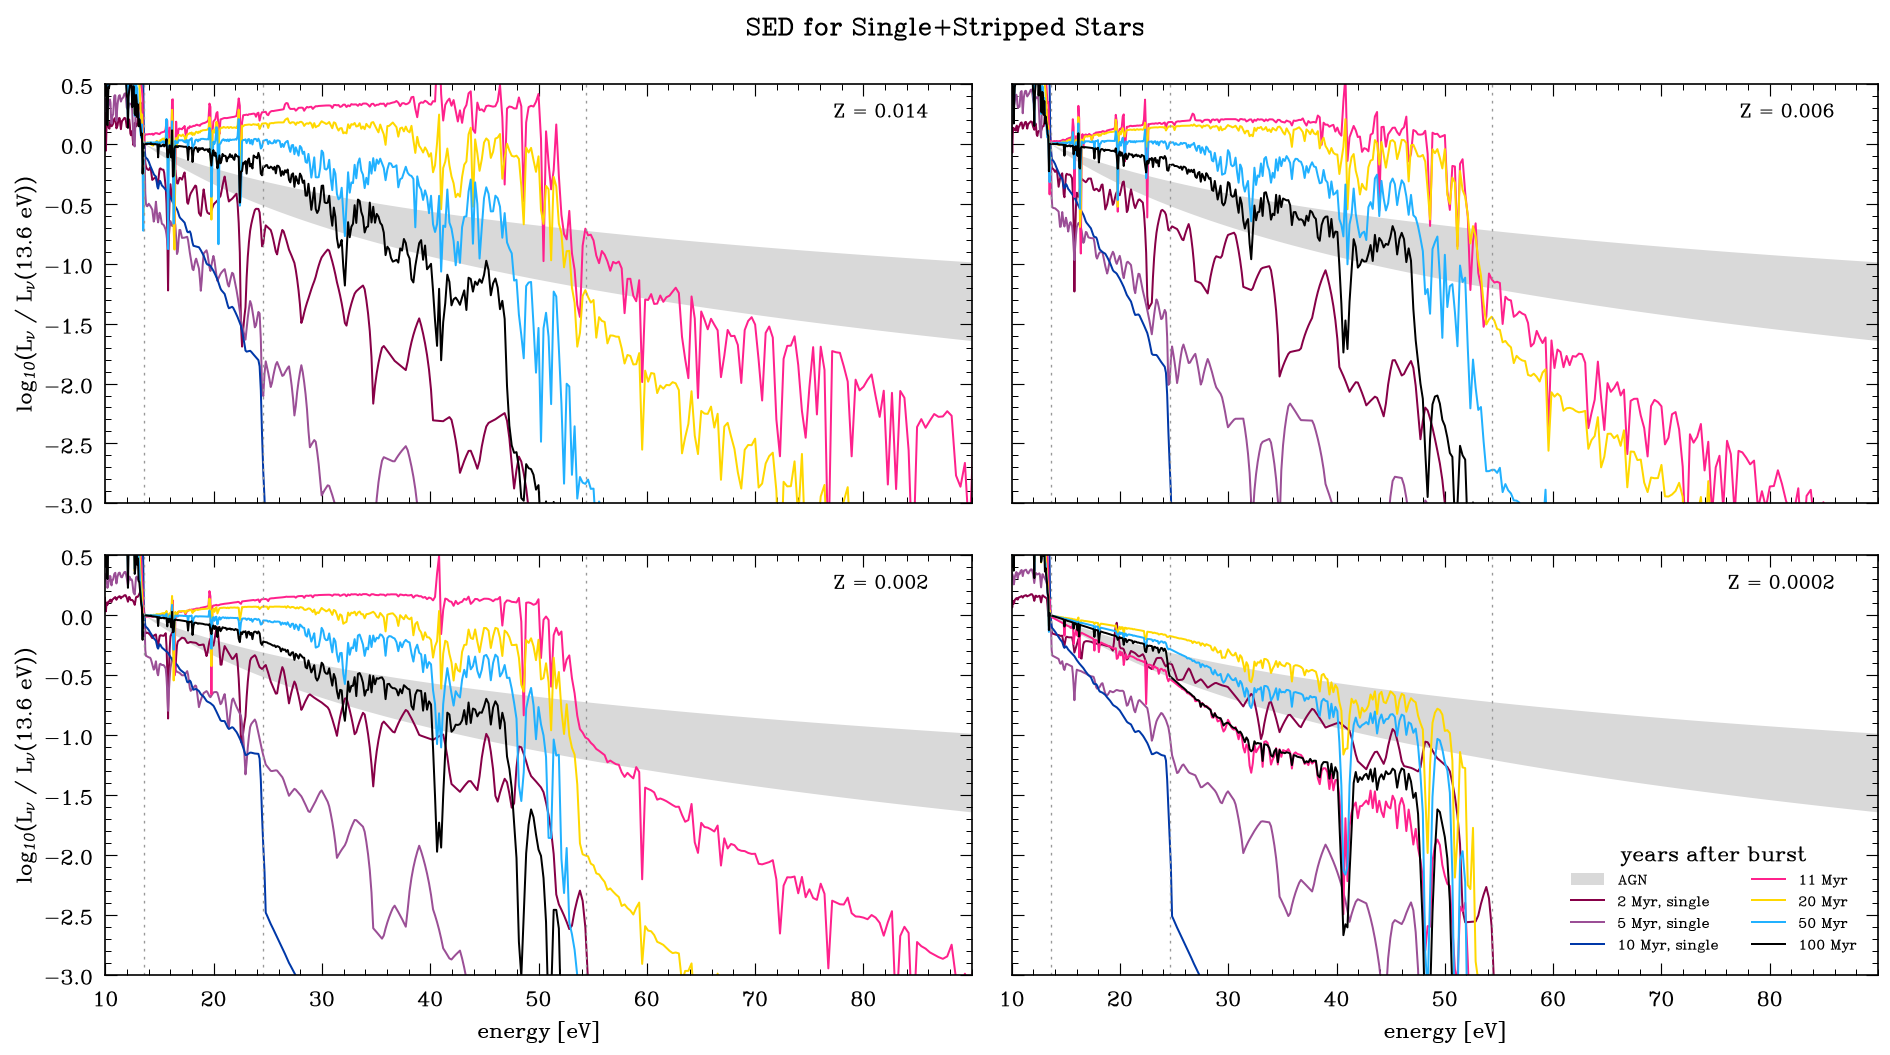

In [24]:
# 2 rows, 2 columns: one panel per metallicity
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, Z in zip(axes.ravel(), metallicities):
    plot_population_shape(ax, Z)

for ax in axes[1, :]:
    ax.set_xlabel("energy [eV]")
axes[1, 0].set_xticks(np.arange(10, 81, 10))      
for ax in axes[:, 0]:
    ax.set_ylabel(r"log$_{10}$(L$_\nu$ / L$_\nu$(13.6 eV))")
axes[1, 1].legend(frameon=False, title="years after burst", ncol=2, fontsize=10, loc="lower right")    
fig.suptitle("SED for Single+Stripped Stars")
fig.tight_layout()
fig.savefig("g19_fig7_population.png", dpi=200)
plt.show()